In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("../data/raw/cs-training.csv")

df = df.drop(columns=["Unnamed: 0"])
df = df[df["age"] > 0]

df = df[
    ~df["NumberOfTimes90DaysLate"].isin([96, 98])
]

df.shape

(149730, 11)

In [3]:
df["MonthlyIncomeMissing"] = df["MonthlyIncome"].isnull().astype(int)
df["DependentsMissing"] = df["NumberOfDependents"].isnull().astype(int)

In [4]:
X = df.drop(columns=["SeriousDlqin2yrs"])
y = df["SeriousDlqin2yrs"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [5]:
income_median = X_train["MonthlyIncome"].median()
dependents_median = X_train["NumberOfDependents"].median()

X_train = X_train.copy()
X_test = X_test.copy()

X_train["MonthlyIncome"] = X_train["MonthlyIncome"].fillna(income_median)
X_test["MonthlyIncome"] = X_test["MonthlyIncome"].fillna(income_median)

X_train["NumberOfDependents"] = (
    X_train["NumberOfDependents"].fillna(dependents_median)
)

X_test["NumberOfDependents"] = (
    X_test["NumberOfDependents"].fillna(dependents_median)
)

In [6]:
print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

0
0


In [7]:
scaler_all = StandardScaler()

X_train_all_scaled = scaler_all.fit_transform(X_train)
X_test_all_scaled = scaler_all.transform(X_test)

model_all = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_all.fit(X_train_all_scaled, y_train)

prob_all = model_all.predict_proba(X_test_all_scaled)[:, 1]

auc_all = roc_auc_score(y_test, prob_all)

print("Model A ROC-AUC:", auc_all)

Model A ROC-AUC: 0.8072002119824739


In [8]:
selected_features = [
    "RevolvingUtilizationOfUnsecuredLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "age",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents",
    "MonthlyIncomeMissing",
    "DependentsMissing"
]

In [9]:
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

scaler_selected = StandardScaler()

X_train_selected_scaled = scaler_selected.fit_transform(
    X_train_selected
)

X_test_selected_scaled = scaler_selected.transform(
    X_test_selected
)

In [10]:
model_selected = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_selected.fit(
    X_train_selected_scaled,
    y_train
)

prob_selected = model_selected.predict_proba(
    X_test_selected_scaled
)[:, 1]

auc_selected = roc_auc_score(
    y_test,
    prob_selected
)

print("Model B ROC-AUC:", auc_selected)

Model B ROC-AUC: 0.8065747406489602


In [11]:
comparison = pd.DataFrame({
    "Model": [
        "All Features",
        "IV Selected Features"
    ],
    "ROC_AUC": [
        auc_all,
        auc_selected
    ]
})

comparison

,Model,ROC_AUC
0,All Features,0.807200
1,IV Selected Features,0.806575


In [12]:
woe_features = [
    "RevolvingUtilizationOfUnsecuredLines",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "age",
    "DebtRatio",
    "MonthlyIncome"
]

In [13]:
X_train_woe = X_train[woe_features].copy()
X_test_woe = X_test[woe_features].copy()

In [14]:
age_train_bin, age_bins = pd.qcut(
    X_train_woe["age"],
    q=10,
    retbins=True,
    duplicates="drop"
)

In [15]:
age_bins[0] = -np.inf
age_bins[-1] = np.inf

In [16]:
X_train_woe["age_bin"] = pd.cut(
    X_train_woe["age"],
    bins=age_bins,
    include_lowest=True
)

X_test_woe["age_bin"] = pd.cut(
    X_test_woe["age"],
    bins=age_bins,
    include_lowest=True
)

In [17]:
age_temp = pd.DataFrame({
    "bin": X_train_woe["age_bin"],
    "target": y_train
})

In [18]:
age_table = (
    age_temp.groupby("bin", observed=False)["target"]
    .agg(["count", "sum"])
)

age_table["bad"] = age_table["sum"]
age_table["good"] = age_table["count"] - age_table["bad"]

age_table["dist_good"] = (
    age_table["good"] / age_table["good"].sum()
)

age_table["dist_bad"] = (
    age_table["bad"] / age_table["bad"].sum()
)

epsilon = 1e-10

age_table["woe"] = np.log(
    (age_table["dist_good"] + epsilon) /
    (age_table["dist_bad"] + epsilon)
)

age_table

,count,sum,bad,good,dist_good,dist_bad,woe
bin,,,,,,,
"(-inf, 33.0]",13540,1493,1493,12047,0.107677,0.188916,-0.562165
"(33.0, 39.0]",11942,1131,1131,10811,0.096629,0.143110,-0.392731
"(39.0, 44.0]",12580,1053,1053,11527,0.103029,0.133241,-0.257144
"(44.0, 48.0]",11742,941,941,10801,0.096540,0.119069,-0.209743
"(48.0, 52.0]",11892,925,925,10967,0.098024,0.117044,-0.177341
"(52.0, 56.0]",11388,752,752,10636,0.095065,0.095154,-0.000930
"(56.0, 61.0]",13481,664,664,12817,0.114559,0.084019,0.310052
"(61.0, 65.0]",10369,398,398,9971,0.089121,0.050361,0.570791
"(65.0, 72.0]",11364,307,307,11057,0.098828,0.038846,0.933778


In [19]:
age_woe_map = age_table["woe"].to_dict()

In [20]:
X_train_woe["age_woe"] = (
    X_train_woe["age_bin"].map(age_woe_map).astype(float)
)

X_test_woe["age_woe"] = (
    X_test_woe["age_bin"].map(age_woe_map).astype(float)
)

In [21]:
X_train_woe[
    ["age", "age_bin", "age_woe"]
].head(10)

,age,age_bin,age_woe
6055,24,"(-inf, 33.0]",-0.562165
149562,72,"(65.0, 72.0]",0.933778
50701,46,"(44.0, 48.0]",-0.209743
148534,45,"(44.0, 48.0]",-0.209743
102986,29,"(-inf, 33.0]",-0.562165
111652,27,"(-inf, 33.0]",-0.562165
148173,67,"(65.0, 72.0]",0.933778
137424,31,"(-inf, 33.0]",-0.562165
2581,78,"(72.0, inf]",1.201200
90719,53,"(52.0, 56.0]",-0.000930


In [22]:
def fit_woe_transform(
    X_train,
    X_test,
    y_train,
    feature,
    bins=10
):
    train_feature = X_train[feature].copy()
    test_feature = X_test[feature].copy()

    # Learn bin boundaries only from training data
    _, bin_edges = pd.qcut(
        train_feature,
        q=bins,
        retbins=True,
        duplicates="drop"
    )

    bin_edges[0] = -np.inf
    bin_edges[-1] = np.inf

    train_bins = pd.cut(
        train_feature,
        bins=bin_edges,
        include_lowest=True
    )

    test_bins = pd.cut(
        test_feature,
        bins=bin_edges,
        include_lowest=True
    )

    temp = pd.DataFrame({
        "bin": train_bins,
        "target": y_train
    })

    table = (
        temp.groupby("bin", observed=False)["target"]
        .agg(["count", "sum"])
    )

    table["bad"] = table["sum"]
    table["good"] = table["count"] - table["bad"]

    table["dist_good"] = (
        table["good"] / table["good"].sum()
    )

    table["dist_bad"] = (
        table["bad"] / table["bad"].sum()
    )

    epsilon = 1e-10

    table["woe"] = np.log(
        (table["dist_good"] + epsilon) /
        (table["dist_bad"] + epsilon)
    )

    woe_map = table["woe"].to_dict()

    train_woe = train_bins.map(
        woe_map
    ).astype(float)

    test_woe = test_bins.map(
        woe_map
    ).astype(float)

    return train_woe, test_woe, table

In [23]:
continuous_woe_features = [
    "RevolvingUtilizationOfUnsecuredLines",
    "age",
    "DebtRatio",
    "MonthlyIncome"
]

In [24]:
X_train_woe_final = pd.DataFrame(index=X_train.index)
X_test_woe_final = pd.DataFrame(index=X_test.index)

woe_tables = {}

In [25]:
for feature in continuous_woe_features:

    train_transformed, test_transformed, table = fit_woe_transform(
        X_train,
        X_test,
        y_train,
        feature,
        bins=10
    )

    X_train_woe_final[feature + "_woe"] = train_transformed
    X_test_woe_final[feature + "_woe"] = test_transformed

    woe_tables[feature] = table

In [26]:
X_train_woe_final.head()

,RevolvingUtilizationOfUnsecuredLines_woe,age_woe,DebtRatio_woe,MonthlyIncome_woe
6055,1.039285,-0.562165,0.379993,-0.243721
149562,0.692176,0.933778,0.108380,-0.243721
50701,-0.281273,-0.209743,-0.265071,-0.398492
148534,-1.423802,-0.209743,0.295829,0.068002
102986,0.692176,-0.562165,0.115762,-0.243721


In [27]:
def delinquency_group(series):

    return pd.cut(
        series,
        bins=[-1, 0, 1, 2, 3, np.inf],
        labels=["0", "1", "2", "3", "4+"]
    )

In [28]:
def fit_grouped_woe(
    train_groups,
    test_groups,
    y_train
):

    temp = pd.DataFrame({
        "group": train_groups,
        "target": y_train
    })

    table = (
        temp.groupby("group", observed=False)["target"]
        .agg(["count", "sum"])
    )

    table["bad"] = table["sum"]
    table["good"] = table["count"] - table["bad"]

    table["dist_good"] = (
        table["good"] / table["good"].sum()
    )

    table["dist_bad"] = (
        table["bad"] / table["bad"].sum()
    )

    epsilon = 1e-10

    table["woe"] = np.log(
        (table["dist_good"] + epsilon) /
        (table["dist_bad"] + epsilon)
    )

    woe_map = table["woe"].to_dict()

    train_woe = train_groups.map(
        woe_map
    ).astype(float)

    test_woe = test_groups.map(
        woe_map
    ).astype(float)

    return train_woe, test_woe, table

In [29]:
delinquency_features = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

In [30]:
for feature in delinquency_features:

    train_groups = delinquency_group(
        X_train[feature]
    )

    test_groups = delinquency_group(
        X_test[feature]
    )

    train_transformed, test_transformed, table = fit_grouped_woe(
        train_groups,
        test_groups,
        y_train
    )

    X_train_woe_final[feature + "_woe"] = train_transformed
    X_test_woe_final[feature + "_woe"] = test_transformed

    woe_tables[feature] = table

In [31]:
X_train_woe_final.head()

,RevolvingUtilizationOfUnsecuredLines_woe,age_woe,DebtRatio_woe,MonthlyIncome_woe,NumberOfTime30-59DaysPastDueNotWorse_woe,NumberOfTime60-89DaysPastDueNotWorse_woe,NumberOfTimes90DaysLate_woe
6055,1.039285,-0.562165,0.379993,-0.243721,0.531736,0.275803,0.378039
149562,0.692176,0.933778,0.108380,-0.243721,0.531736,0.275803,0.378039
50701,-0.281273,-0.209743,-0.265071,-0.398492,0.531736,0.275803,0.378039
148534,-1.423802,-0.209743,0.295829,0.068002,-1.627316,-1.845302,-1.974910
102986,0.692176,-0.562165,0.115762,-0.243721,0.531736,0.275803,0.378039


In [32]:
print(X_train_woe_final.shape)
print(X_test_woe_final.shape)

print("\nMissing train:")
print(X_train_woe_final.isnull().sum())

print("\nMissing test:")
print(X_test_woe_final.isnull().sum())

(119784, 7)
(29946, 7)

Missing train:
RevolvingUtilizationOfUnsecuredLines_woe    0
age_woe                                     0
DebtRatio_woe                               0
MonthlyIncome_woe                           0
NumberOfTime30-59DaysPastDueNotWorse_woe    0
NumberOfTime60-89DaysPastDueNotWorse_woe    0
NumberOfTimes90DaysLate_woe                 0
dtype: int64

Missing test:
RevolvingUtilizationOfUnsecuredLines_woe    0
age_woe                                     0
DebtRatio_woe                               0
MonthlyIncome_woe                           0
NumberOfTime30-59DaysPastDueNotWorse_woe    0
NumberOfTime60-89DaysPastDueNotWorse_woe    0
NumberOfTimes90DaysLate_woe                 0
dtype: int64


In [33]:
model_woe = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_woe.fit(
    X_train_woe_final,
    y_train
)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [34]:
prob_woe = model_woe.predict_proba(
    X_test_woe_final
)[:, 1]

In [35]:
auc_woe = roc_auc_score(
    y_test,
    prob_woe
)

print("WOE Logistic Regression ROC-AUC:", auc_woe)

WOE Logistic Regression ROC-AUC: 0.8491740174188944


In [36]:
comparison = pd.DataFrame({
    "Model": [
        "All Features",
        "IV Selected Features",
        "WOE Logistic Regression"
    ],
    "ROC_AUC": [
        auc_all,
        auc_selected,
        auc_woe
    ]
})

comparison

,Model,ROC_AUC
0,All Features,0.807200
1,IV Selected Features,0.806575
2,WOE Logistic Regression,0.849174


In [37]:
woe_coefficients = pd.DataFrame({
    "Feature": X_train_woe_final.columns,
    "Coefficient": model_woe.coef_[0]
})

woe_coefficients = woe_coefficients.sort_values(
    "Coefficient"
)

woe_coefficients

,Feature,Coefficient
2,DebtRatio_woe,-0.654881
0,RevolvingUtilizationOfUnsecuredLines_woe,-0.633582
6,NumberOfTimes90DaysLate_woe,-0.546183
4,NumberOfTime30-59DaysPastDueNotWorse_woe,-0.531544
1,age_woe,-0.449111
5,NumberOfTime60-89DaysPastDueNotWorse_woe,-0.402403
3,MonthlyIncome_woe,-0.221905


In [38]:
y_pred_woe = (prob_woe >= 0.50).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_woe))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_woe))

Confusion Matrix:
[[27729   241]
 [ 1608   368]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97     27970
           1       0.60      0.19      0.28      1976

    accuracy                           0.94     29946
   macro avg       0.77      0.59      0.63     29946
weighted avg       0.92      0.94      0.92     29946



In [39]:
woe_results = []

for threshold in np.arange(0.05, 0.55, 0.05):
    y_pred_threshold = (prob_woe >= threshold).astype(int)

    woe_results.append({
        "threshold": threshold,
        "precision": precision_score(y_test, y_pred_threshold),
        "recall": recall_score(y_test, y_pred_threshold),
        "f1": f1_score(y_test, y_pred_threshold)
    })

woe_threshold_df = pd.DataFrame(woe_results)

woe_threshold_df

,threshold,precision,recall,f1
0,0.05,0.175328,0.799089,0.287561
1,0.10,0.277438,0.596154,0.378656
2,0.15,0.361307,0.492409,0.416792
3,0.20,0.416171,0.424595,0.420341
4,0.25,0.458627,0.361842,0.404526
5,0.30,0.490998,0.303644,0.375235
6,0.35,0.531621,0.272267,0.360107
7,0.40,0.551282,0.239372,0.333804
8,0.45,0.579376,0.216093,0.314781
9,0.50,0.604269,0.186235,0.284720


In [40]:
best_woe_row = woe_threshold_df.loc[
    woe_threshold_df["f1"].idxmax()
]

best_woe_row

threshold    0.200000
precision    0.416171
recall       0.424595
f1           0.420341
Name: 3, dtype: float64

In [41]:
best_woe_threshold = best_woe_row["threshold"]

y_pred_woe_best = (
    prob_woe >= best_woe_threshold
).astype(int)

In [42]:
print("Best WOE threshold:", best_woe_threshold)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_woe_best))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_woe_best))

Best WOE threshold: 0.2

Confusion Matrix:
[[26793  1177]
 [ 1137   839]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96     27970
           1       0.42      0.42      0.42      1976

    accuracy                           0.92     29946
   macro avg       0.69      0.69      0.69     29946
weighted avg       0.92      0.92      0.92     29946



In [44]:
import matplotlib.pyplot as plt

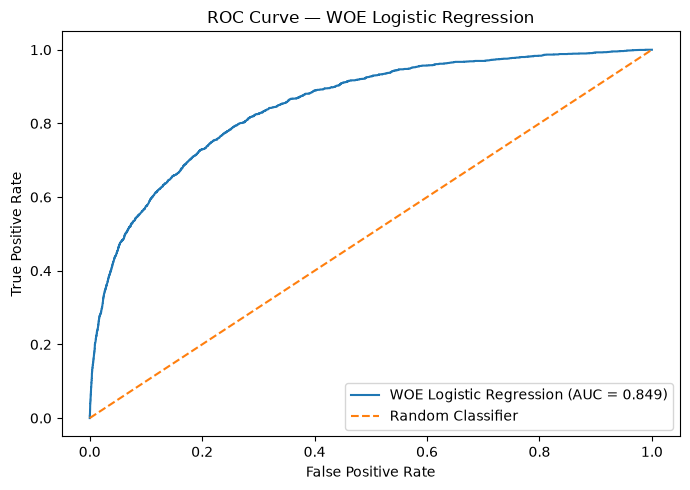

In [45]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, prob_woe)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"WOE Logistic Regression (AUC = {auc_woe:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — WOE Logistic Regression")
plt.legend()

plt.tight_layout()

plt.savefig(
    "../reports/figures/roc_curve_woe.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:
woe_results = []

for threshold in np.arange(0.05, 0.55, 0.05):
    y_pred_threshold = (prob_woe >= threshold).astype(int)

    woe_results.append({
        "threshold": threshold,
        "precision": precision_score(y_test, y_pred_threshold),
        "recall": recall_score(y_test, y_pred_threshold),
        "f1": f1_score(y_test, y_pred_threshold)
    })

woe_threshold_df = pd.DataFrame(woe_results)

woe_threshold_df

,threshold,precision,recall,f1
0,0.05,0.175328,0.799089,0.287561
1,0.10,0.277438,0.596154,0.378656
2,0.15,0.361307,0.492409,0.416792
3,0.20,0.416171,0.424595,0.420341
4,0.25,0.458627,0.361842,0.404526
5,0.30,0.490998,0.303644,0.375235
6,0.35,0.531621,0.272267,0.360107
7,0.40,0.551282,0.239372,0.333804
8,0.45,0.579376,0.216093,0.314781
9,0.50,0.604269,0.186235,0.284720


In [47]:
best_woe_row = woe_threshold_df.loc[
    woe_threshold_df["f1"].idxmax()
]

best_woe_row

threshold    0.200000
precision    0.416171
recall       0.424595
f1           0.420341
Name: 3, dtype: float64

In [48]:
best_woe_threshold = best_woe_row["threshold"]

y_pred_woe_best = (
    prob_woe >= best_woe_threshold
).astype(int)

print("Best WOE threshold:", best_woe_threshold)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_woe_best))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_woe_best))

Best WOE threshold: 0.2

Confusion Matrix:
[[26793  1177]
 [ 1137   839]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96     27970
           1       0.42      0.42      0.42      1976

    accuracy                           0.92     29946
   macro avg       0.69      0.69      0.69     29946
weighted avg       0.92      0.92      0.92     29946



In [49]:
best_woe_row = woe_threshold_df.loc[
    woe_threshold_df["f1"].idxmax()
]

best_woe_row

threshold    0.200000
precision    0.416171
recall       0.424595
f1           0.420341
Name: 3, dtype: float64

In [50]:
best_woe_threshold = best_woe_row["threshold"]

y_pred_woe_best = (
    prob_woe >= best_woe_threshold
).astype(int)

print("Best WOE threshold:", best_woe_threshold)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_woe_best))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_woe_best))

Best WOE threshold: 0.2

Confusion Matrix:
[[26793  1177]
 [ 1137   839]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96     27970
           1       0.42      0.42      0.42      1976

    accuracy                           0.92     29946
   macro avg       0.69      0.69      0.69     29946
weighted avg       0.92      0.92      0.92     29946



In [51]:
results_df = pd.DataFrame({
    "ActualDefault": y_test.values,
    "PD": prob_woe
})

results_df.head(10)

,ActualDefault,PD
0,1,0.048300
1,0,0.067079
2,0,0.150229
3,0,0.009582
4,0,0.016105
5,0,0.022214
6,0,0.029134
7,0,0.079490
8,0,0.030105
9,0,0.064069


In [52]:
results_df["RiskBand"] = pd.cut(
    results_df["PD"],
    bins=[0, 0.05, 0.10, 0.20, 0.40, 1],
    labels=[
        "Very Low",
        "Low",
        "Moderate",
        "High",
        "Very High"
    ],
    include_lowest=True
)

In [53]:
risk_summary = (
    results_df.groupby(
        "RiskBand",
        observed=False
    )
    .agg(
        borrowers=("PD", "count"),
        avg_pd=("PD", "mean"),
        actual_default_rate=("ActualDefault", "mean")
    )
)

risk_summary

,borrowers,avg_pd,actual_default_rate
RiskBand,,,
Very Low,20940,0.021103,0.018959
Low,4760,0.072100,0.084244
Moderate,2230,0.135921,0.152018
High,1158,0.275766,0.316062
Very High,858,0.606543,0.551282


In [54]:
LGD_ASSUMPTION = 0.45
EAD_ASSUMPTION = 10000

In [55]:
results_df["LGD"] = LGD_ASSUMPTION
results_df["EAD"] = EAD_ASSUMPTION

results_df["ExpectedLoss"] = (
    results_df["PD"]
    * results_df["LGD"]
    * results_df["EAD"]
)

results_df[
    [
        "PD",
        "LGD",
        "EAD",
        "ExpectedLoss"
    ]
].head(10)

,PD,LGD,EAD,ExpectedLoss
0,0.048300,0.45,10000,217.348880
1,0.067079,0.45,10000,301.857282
2,0.150229,0.45,10000,676.030953
3,0.009582,0.45,10000,43.120423
4,0.016105,0.45,10000,72.474196
5,0.022214,0.45,10000,99.962441
6,0.029134,0.45,10000,131.101222
7,0.079490,0.45,10000,357.703168
8,0.030105,0.45,10000,135.470930
9,0.064069,0.45,10000,288.308644


In [56]:
results_df.groupby(
    "RiskBand",
    observed=False
)["ExpectedLoss"].agg(
    ["count", "mean", "sum"]
)

,count,mean,sum
RiskBand,,,
Very Low,20940,94.965533,1.988578e+06
Low,4760,324.450197,1.544383e+06
Moderate,2230,611.645736,1.363970e+06
High,1158,1240.948285,1.437018e+06
Very High,858,2729.444796,2.341864e+06


In [57]:
from sklearn.metrics import brier_score_loss

brier_score = brier_score_loss(
    y_test,
    prob_woe
)

print("Brier Score:", brier_score)

Brier Score: 0.04985492010864447


In [58]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y_test,
    prob_woe,
    n_bins=10,
    strategy="quantile"
)

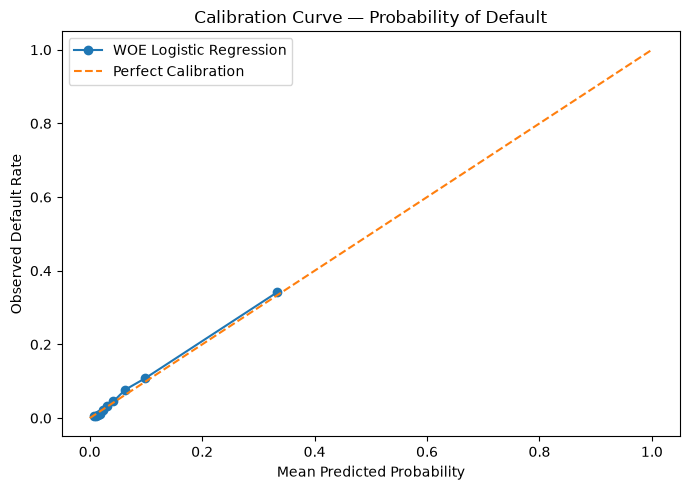

In [59]:
plt.figure(figsize=(7, 5))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="WOE Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Default Rate")
plt.title("Calibration Curve — Probability of Default")

plt.legend()
plt.tight_layout()

plt.savefig(
    "../reports/figures/calibration_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Probability of Default and Expected Loss

The WOE logistic regression model was used to estimate an individual Probability of Default (PD) for each borrower.

Borrowers were subsequently segmented into risk bands based on their estimated PD. Observed default rates increased consistently across the risk categories, indicating that the model provides meaningful risk differentiation.

Because the dataset does not contain observed Loss Given Default (LGD) or Exposure at Default (EAD), Expected Loss was calculated using illustrative assumptions:

- LGD: 45%
- EAD: 10,000 monetary units

Expected Loss was therefore calculated as:

EL = PD × LGD × EAD

These LGD and EAD values are scenario assumptions and should not be interpreted as observed portfolio values.